# Week 10 — Data-Centric AI: Error Analysis, Data Enhancements, and MLP_B Refit

**===== WEEK 10 START =====**

Objective: preserve the Week 9 validation-selected MLP_B architecture, diagnose training errors, introduce three sequential data improvements, select a final version using validation MAE, and evaluate the locked selection on the already-studied historical test period. **The Week 9 test period is not a new independent holdout.**

## 1. Project environment and original model safeguards

Use the existing ADAN8888 repository. The source refuses to silently refit the Week 9 reference estimator: it checks the saved MLP_B artifact and Week 9 manifest SHA-256, then reproduces the prior validation metrics before any new candidate is fitted.

In [11]:
from pathlib import Path
import importlib.util
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for initial in (Path.cwd().resolve(), Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd().resolve())
             for p in (initial, *initial.parents)
             if (p / 'Src' / 'week10_src_data_enhancement_error_analysis_refit.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the original ADAN8888 repository in VS Code, then rerun this cell.')
assert (ROOT / 'Src' / 'week5_src_features_dimensionality.py').is_file()
assert (ROOT / 'Src' / 'week8_src_mlp_neural_network.py').is_file()
assert (ROOT / 'Models' / 'week8' / 'week8_selected_mlp_neural_network.joblib').is_file()
assert (ROOT / 'Models' / 'week9' / 'week9_final_model_manifest.json').is_file()
assert (ROOT / 'Reports' / 'week9' / 'week9_tables' / 'week9_selection_lock.json').is_file()
print('Prior-week source, original saved estimator, and Week 9 model-selection evidence found.')

Prior-week source, original saved estimator, and Week 9 model-selection evidence found.


In [12]:
spec = importlib.util.spec_from_file_location('adan_week10_source',
    ROOT / 'Src' / 'week10_src_data_enhancement_error_analysis_refit.py')
week10 = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = week10
spec.loader.exec_module(week10)
print('Week 10 source imported successfully.')

Week 10 source imported successfully.


## 2. Data improvement design

We keep MLP_B with hidden layers **(64, 32)** and Week 8 fixed hyperparameters. The three additions are tested incrementally:

1. **Temporal demand history:** exact-month lags 1, 2, 11, 12; complete 3-month rolling mean; month/year demand changes and missingness.
2. **Data quality and operational measures:** recovered original numeric inputs, legitimate nonnegative counts, safe load factor and schedule completion ratios, missing indicators, training-only imputation.
3. **Seasonal and route context:** cyclical forecast-month features, calendar exposure, time trend, and training-only carrier/airport/route frequency encoding.

The selected model may use more input connections than the original 2-feature network, even though the hidden-layer architecture and optimizer remain fixed.

## 3. Run all stages and lock the model before historical test evaluation

This is the single primary execution cell. On an unfinished project, it checks the Week 9 reference, fits enhanced candidates on training, chooses the validation winner, writes the selection lock, and only then records the selected model's historical test performance. If a completed result already exists, it **loads the saved result without rescoring test data**.

The full BTS dataset is processed locally. Metrics from the synthetic smoke test must **never** be copied into the report.

In [13]:
results = week10.run_week10(ROOT, save_full_data=False, threads=4)
display(results[['Model','Split','Rows','InputFeatures','TrainableParameters','MAE','RMSE','R2']].round(4))

Existing Week 10 final evaluation detected. Using saved tables; NOT scoring test again.


,Model,Split,Rows,InputFeatures,TrainableParameters,MAE,RMSE,R2
0,MLP_B_original_PCA,Training,1062603,2,2305,1161.6278,2236.2033,0.9169
1,MLP_B_original_PCA,Validation,239395,2,2305,1143.1952,1988.7780,0.9399
2,MLP_B_temporal,Training,1062603,16,3201,808.1664,1434.7893,0.9658
3,MLP_B_temporal,Validation,239395,16,3201,809.3316,1299.8096,0.9743
4,MLP_B_temporal_quality,Training,1062603,30,4097,801.5727,1428.7769,0.9661
5,MLP_B_temporal_quality,Validation,239395,30,4097,819.8029,1330.5446,0.9731
6,MLP_B_enhanced_refit,Training,1062603,38,4609,704.1294,1203.0290,0.9760
7,MLP_B_enhanced_refit,Validation,239395,38,4609,870.3522,1466.9507,0.9673
8,MLP_B_temporal,Test,264291,16,3201,790.2854,1283.1248,0.9732


## 4. Compare the original model and three data-enhancement stages on validation

Validation MAE is the primary winner criterion, with validation RMSE and model size used only for ties. Positive error reduction means improvement. Some changes can legitimately *worsen* performance; those must be reported rather than hidden.

In [14]:
tables = ROOT / 'Reports' / 'week10' / 'week10_tables'
figures = ROOT / 'Reports' / 'week10' / 'week10_figures'
ablation = pd.read_csv(tables / 'week10_incremental_ablation.csv')
ranking = pd.read_csv(tables / 'week10_validation_ranking.csv')
selection = json.loads((tables / 'week10_selection_lock.json').read_text(encoding='utf-8'))
display(ablation.round(4))
print('Locked selected model:', selection['Winner'])
display(ranking[['Model','MAE','RMSE','InputFeatures','TrainableParameters']].round(4))

,Stage,Validation_MAE,Validation_RMSE,InputFeatures,TrainableParameters,MAE_Improvement_vs_Original,MAE_Improvement_vs_Previous
0,MLP_B_original_PCA,1143.1952,1988.7780,2,2305,0.0000,NaN
1,MLP_B_temporal,809.3316,1299.8096,16,3201,333.8636,333.8636
2,MLP_B_temporal_quality,819.8029,1330.5446,30,4097,323.3923,-10.4714
3,MLP_B_enhanced_refit,870.3522,1466.9507,38,4609,272.8429,-50.5493


Locked selected model: MLP_B_temporal


,Model,MAE,RMSE,InputFeatures,TrainableParameters
0,MLP_B_temporal,809.3316,1299.8096,16,3201
1,MLP_B_temporal_quality,819.8029,1330.5446,30,4097
2,MLP_B_enhanced_refit,870.3522,1466.9507,38,4609
3,MLP_B_original_PCA,1143.1952,1988.7780,2,2305


## 5. Training-error diagnosis and data quality

- The training residual groupings identify error concentrations by observed-demand bands, target month, carrier, and route. 
- These are **in-sample descriptions**, not independent generalization estimates. 
- The missingness tables show how train-fitted rules are applied consistently to later partitions.

In [15]:
for name in ['week10_MLP_B_original_PCA_training_errors_by_DemandBand.csv',
             'week10_MLP_B_enhanced_refit_training_errors_by_DemandBand.csv',
             'week10_feature_manifest.csv', 'week10_test_missingness.csv']:
    path = tables / name
    if not path.exists():
        raise FileNotFoundError(f'Missing expected diagnostic output: {name}')
    print('\n', name)
    display(pd.read_csv(path).head(12))


 week10_MLP_B_original_PCA_training_errors_by_DemandBand.csv


,DemandBand,Rows,MeanActual,MAE,MeanResidual,RMSE
0,Zero,18950,0.000000,89.398186,-89.398186,553.907629
1,1-1000,289232,286.592542,558.181961,-516.781781,1383.408835
2,1001-10000,610805,3797.085088,995.343267,-129.888390,1731.040743
3,10001-50000,139698,19521.403277,3095.729021,706.845539,4274.858921
4,Above50000,3918,60086.280500,7856.858870,5767.616262,9732.613806



 week10_MLP_B_enhanced_refit_training_errors_by_DemandBand.csv


,DemandBand,Rows,MeanActual,MAE,MeanResidual,RMSE
0,Zero,18950,0.000000,86.281099,-86.281099,354.185977
1,1-1000,289232,286.592542,377.717072,-298.785495,709.093052
2,1001-10000,610805,3797.085088,658.195434,143.251282,999.931046
3,10001-50000,139698,19521.403277,1580.943424,776.637323,2225.759010
4,Above50000,3918,60086.280500,3686.437948,3084.619118,4720.110986



 week10_feature_manifest.csv


,Feature,TrainingMedianImputation
0,PC1,0.584955
1,PC2,0.062465
2,PassengersLog1p,7.827241
3,PassengersMissing,0.000000
4,SeatsLog1p,8.137688
5,SeatsMissing,0.000000
6,DepScheduledLog1p,3.465736
7,DepScheduledMissing,0.000000
8,DepPerformedLog1p,3.496508
9,DepPerformedMissing,0.000000



 week10_test_missingness.csv


,Feature,MissingBeforeImputation,MissingAfterImputation,Split
0,PC1,0,0,Test
1,PC2,0,0,Test
2,PassengersLog1p,0,0,Test
3,PassengersMissing,0,0,Test
4,SeatsLog1p,0,0,Test
5,SeatsMissing,0,0,Test
6,DepScheduledLog1p,0,0,Test
7,DepScheduledMissing,0,0,Test
8,DepPerformedLog1p,0,0,Test
9,DepPerformedMissing,0,0,Test


## 6. Training, validation, and historical test performance of the selected model

- The historical test period was already examined in Week 9. The Week 10 test result provides a required comparison, **not** a new independent holdout. 
- The original model's Week 9 test metrics are reused if it remains the winner.

In [16]:
last = pd.read_csv(tables / 'week10_train_validation_test_metrics.csv')
selected = selection['Winner']
display(last[last.Model.eq(selected)][['Split','Rows','MAE','RMSE','R2']].round(4))
test_meta = json.loads((tables / 'week10_final_test_result.json').read_text(encoding='utf-8'))
print('Test mode:', test_meta['TestMode'])
print('Prior Week 9 test reviewed:', test_meta['Week9TestPreviouslyExamined'])

,Split,Rows,MAE,RMSE,R2
2,Training,1062603,808.1664,1434.7893,0.9658
3,Validation,239395,809.3316,1299.8096,0.9743
8,Test,264291,790.2854,1283.1248,0.9732


Test mode: Week 10 selected enhanced model scored once on reused Week 9 test period
Prior Week 9 test reviewed: True


## 7. Diagnostic figures

These are saved from actual local model outputs. When the original model wins, Week 9 test scatter/monthly figures remain the appropriate historical diagnostics rather than being regenerated.

week10_validation_ablation_comparison.png


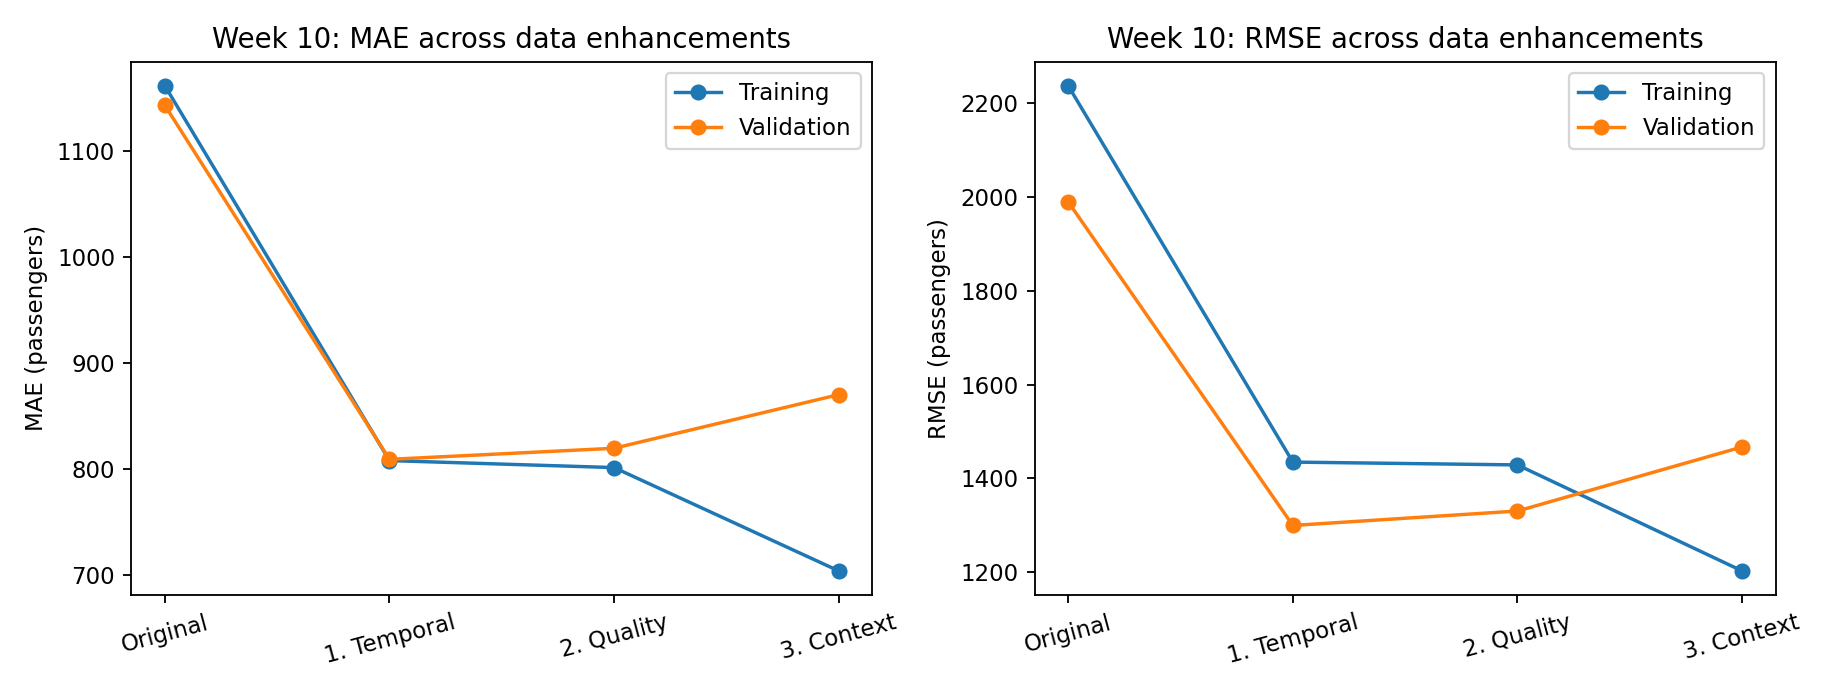

week10_feature_dimension_stages.png


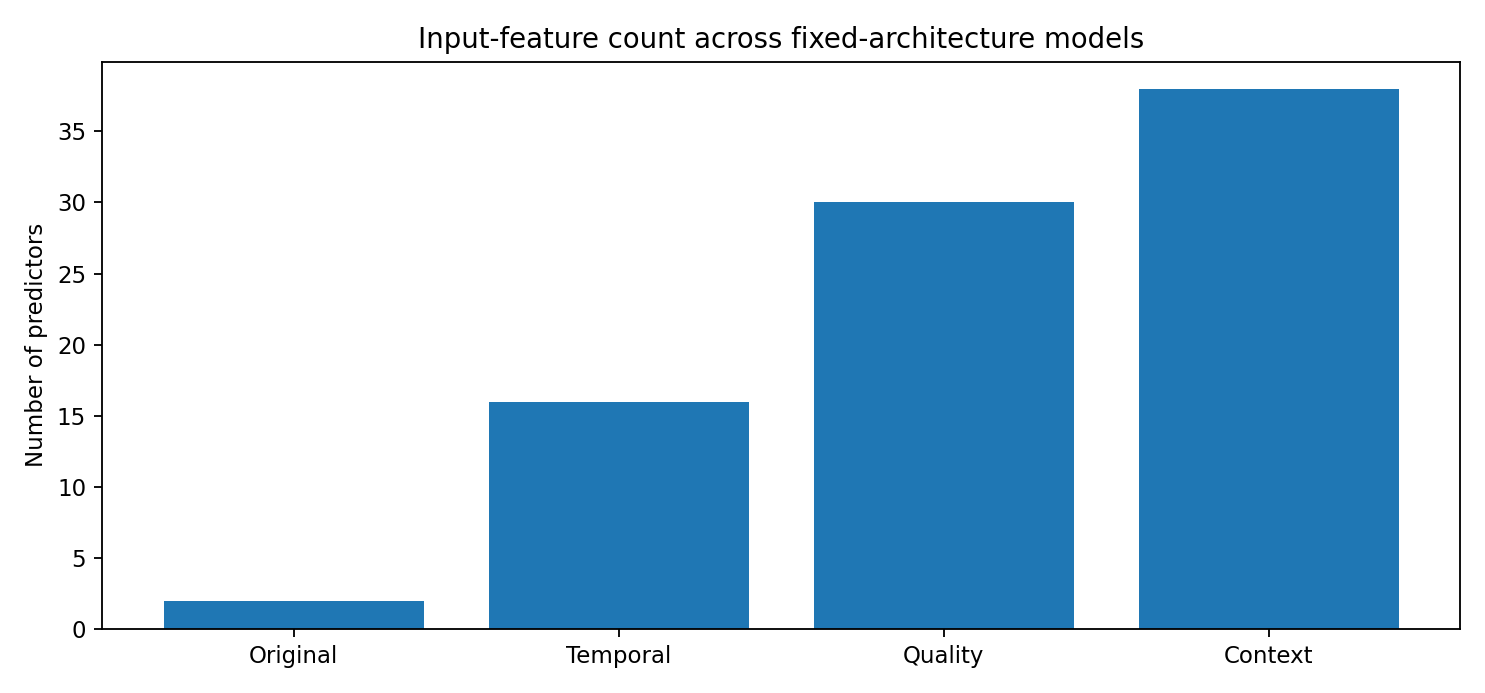

week10_training_demand_band_errors.png


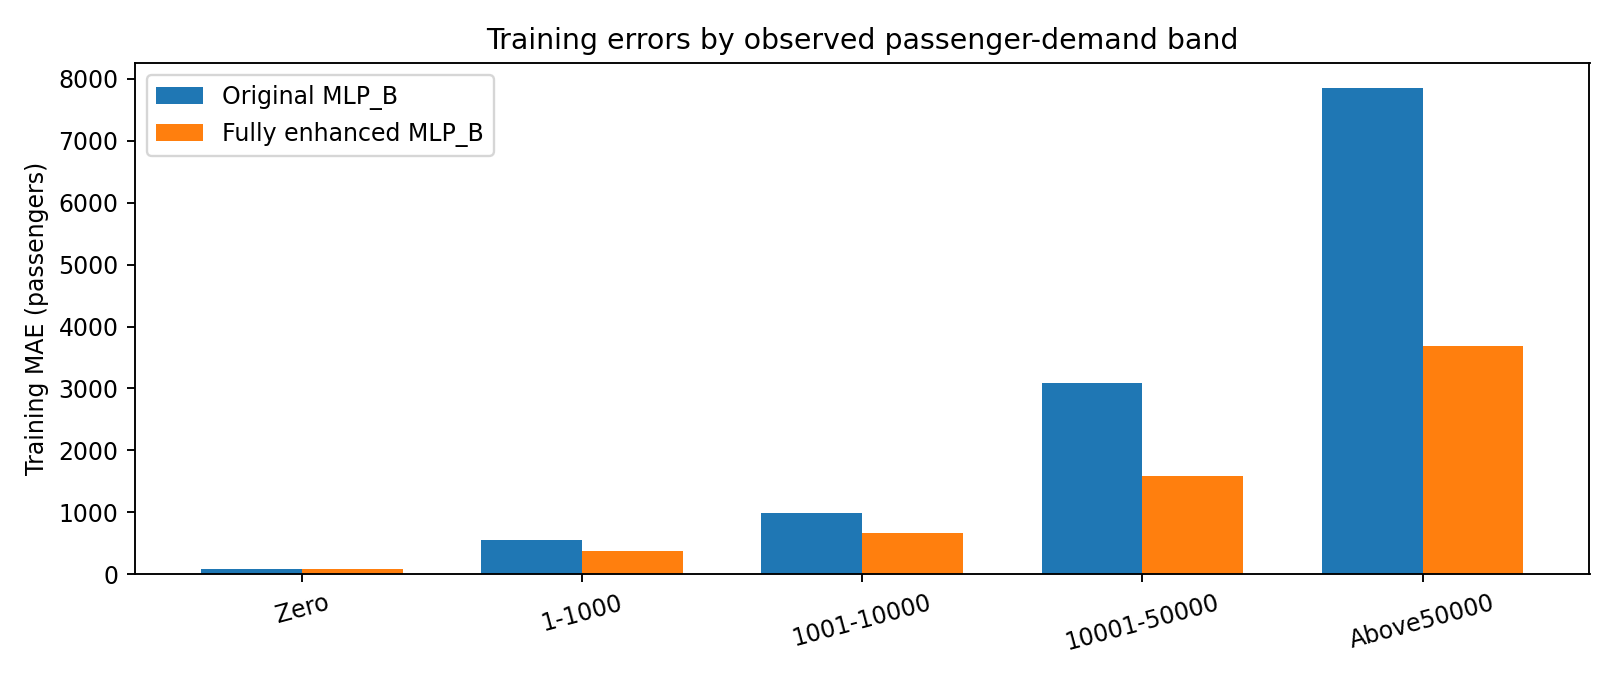

week10_selected_train_validation_test.png


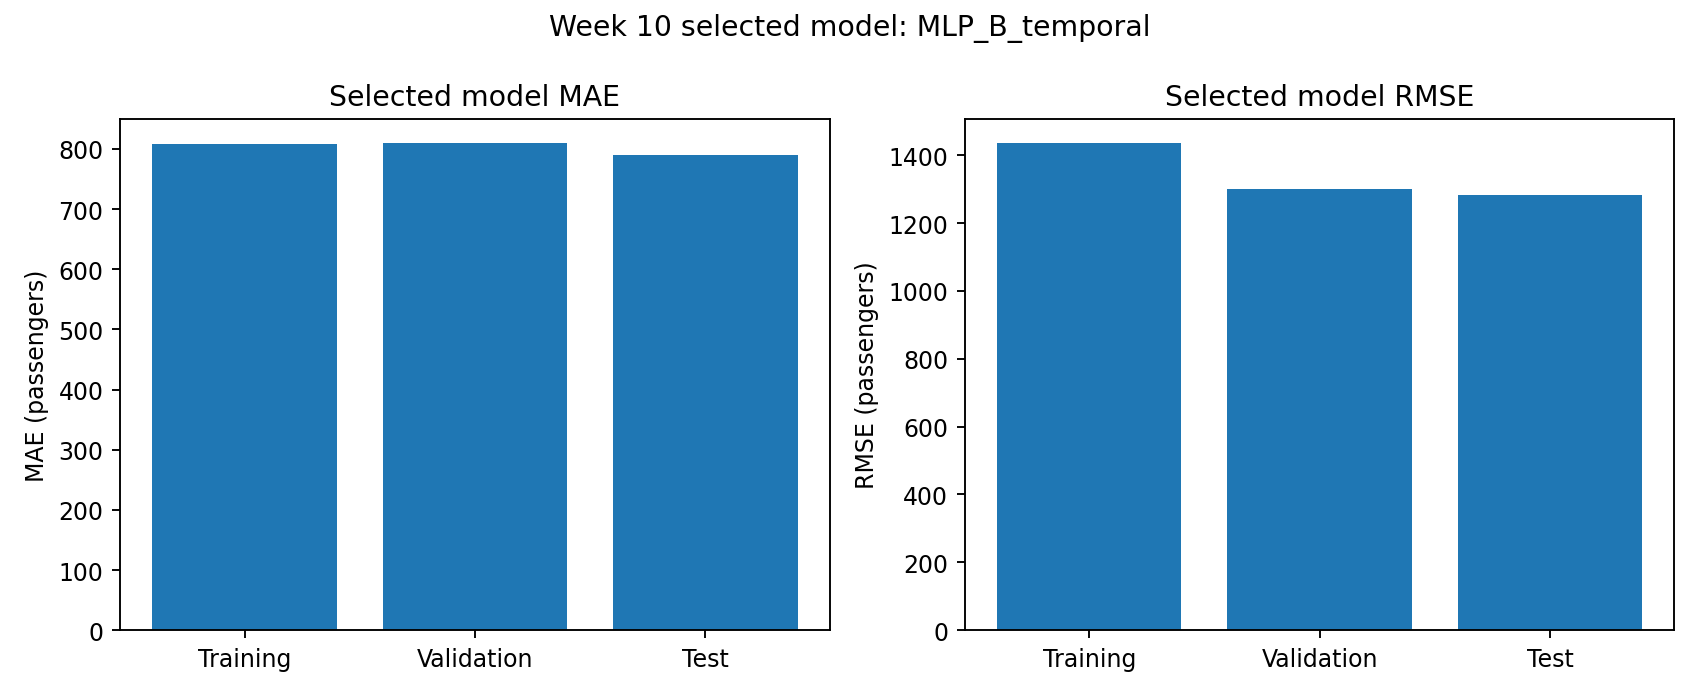

week10_training_monthly_mae_before_after.png


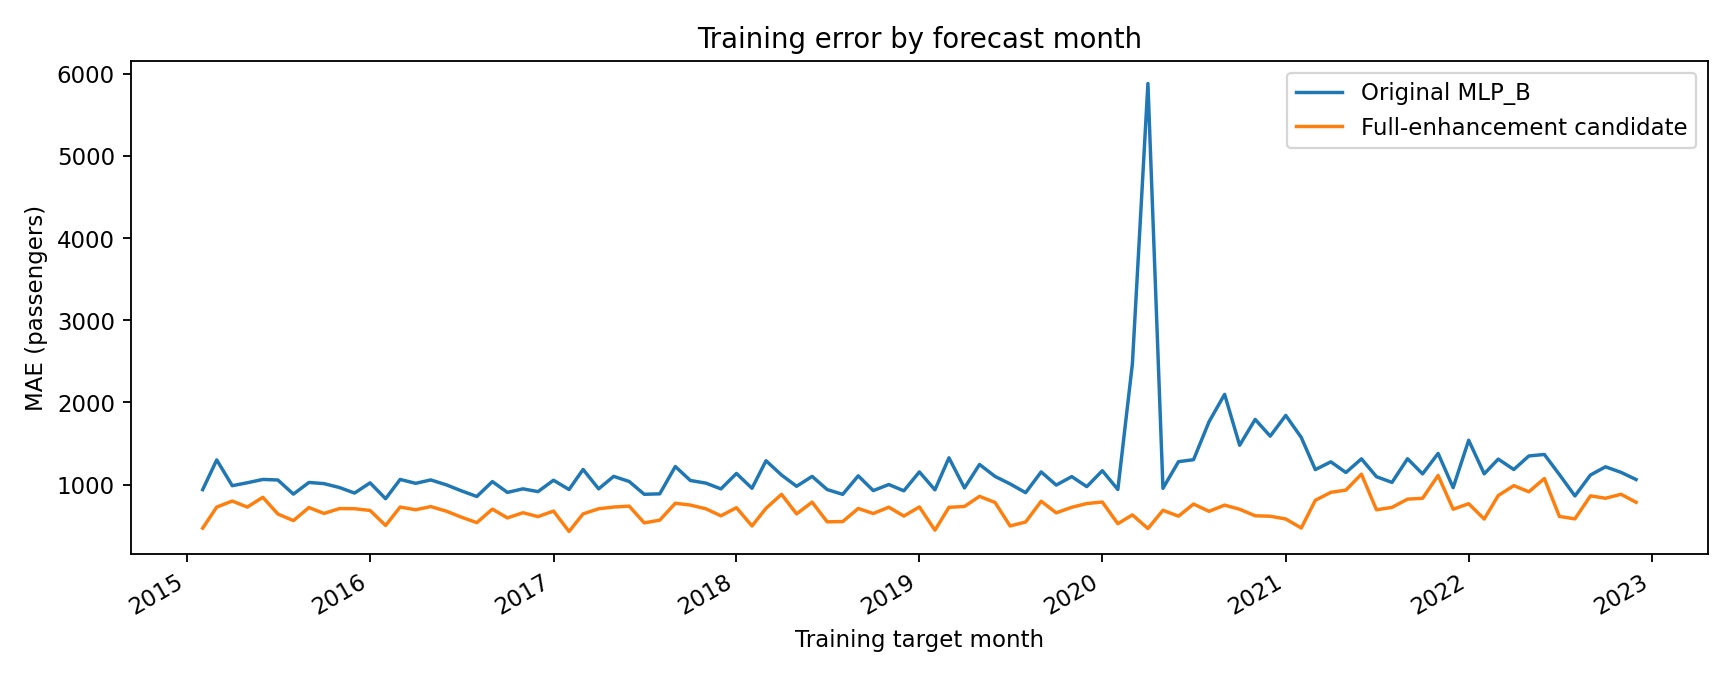

In [17]:
paths = ['week10_validation_ablation_comparison.png',
         'week10_feature_dimension_stages.png',
         'week10_training_demand_band_errors.png',
         'week10_selected_train_validation_test.png',
         'week10_training_monthly_mae_before_after.png']
for name in paths:
    file = figures / name
    if not file.is_file():
        raise FileNotFoundError('Expected figure missing: ' + name)
    print(name)
    display(Image(filename=str(file), width=700))

## 8. Reproducibility and completion checks

No feature transformation is fitted on validation/test. Record counts, targets, and chronological split assignments are unchanged. The final-model bundle includes the training-fitted preprocessing. Do not claim operational readiness until BTS publication latency and business acceptance thresholds are addressed.

In [18]:
required = [
  tables / 'week10_incremental_ablation.csv',
  tables / 'week10_validation_ranking.csv',
  tables / 'week10_train_validation_test_metrics.csv',
  tables / 'week10_selection_lock.json',
  tables / 'week10_final_test_result.json',
  ROOT / 'Models' / 'week10' / 'week10_final_model_manifest.json',
  ROOT / 'Reports' / 'week10' / 'week10_verified_results_for_report.md',
]
assert all(p.exists() for p in required)
assert len(last[last.Split.eq('Training')]) == 4
assert len(last[last.Split.eq('Validation')]) == 4
assert len(last[last.Split.eq('Test')]) == 1
assert test_meta['TestLabelsUsedForSelection'] is False
assert selection['TestEvaluatedAtSelection'] is False
print('All Week 10 checks passed.')
print('===== WEEK 10 END =====')

All Week 10 checks passed.
===== WEEK 10 END =====
